<a href="https://colab.research.google.com/github/JhonWV/Ciencias_Datos/blob/main/Actividad4EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: Jhon Wilfer Virguez Sierra
*   MATRÍCULA: A01841719

In [35]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [36]:
import os
DIR = "/content/drive/MyDrive/TEC/Ciencia de datos"
os.chdir(DIR)

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [37]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [38]:
loan_df = pd.read_csv('/content/drive/MyDrive/TEC/Ciencia de datos/personal_loan.csv')
loan_df

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,0,25,1,49,91108,4,1.6,1.0,0,0,Yes,No,0,0
1,1,45,19,34,90089,3,1.5,1.0,0,No,Yes,No,No,0
2,2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,3,35,9,100,94112,1,2.7,2.0,0,0,0,0,No,0
4,4,35,8,45,91330,4,1.0,2.0,0,0,No,No,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5032,5032,34,9,65,95134,4,1.3,1.0,0,0,No,No,No,Yes
5033,5033,45,20,84,94131,4,1.1,2.0,180,0,No,0,1,0
5034,5034,47,23,148,94551,2,7.5,1.0,0,0,No,1,Yes,Yes
5035,5035,56,32,58,95064,1,1.8,3.0,241,0,No,No,Yes,0



*   **Haz que la columna ID sea el índice del dataframe.**






In [39]:
loan_df = loan_df.set_index("ID")
loan_df

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
0,25,1,49,91108,4,1.6,1.0,0,0,Yes,No,0,0
1,45,19,34,90089,3,1.5,1.0,0,No,Yes,No,No,0
2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2.0,0,0,0,0,No,0
4,35,8,45,91330,4,1.0,2.0,0,0,No,No,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5032,34,9,65,95134,4,1.3,1.0,0,0,No,No,No,Yes
5033,45,20,84,94131,4,1.1,2.0,180,0,No,0,1,0
5034,47,23,148,94551,2,7.5,1.0,0,0,No,1,Yes,Yes



*   **Utiliza el método info() del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?**

Como se aprecia en la tabla siguiente hay 8 columnas (variables) con información númerica; de estas dos (2) son de punto flotante (float64(2)), y seis (6) son de número entero (int64(7)). Asimismo, hay 5 columnas de tipo objeto, que en la libreria Pandas se utiliza  para almacenar texto (object(5)).





In [40]:
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [41]:
# Estadísticas descriptivas de las variables numéricas
loan_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,5037.0,45.411356,11.646805,23.0,35.0,45.0,55.0,144.0
Experience,5037.0,20.122494,11.461278,-3.0,10.0,20.0,30.0,43.0
Income,5037.0,73.898352,46.130504,8.0,39.0,64.0,98.0,224.0
ZIP Code,5037.0,93152.865595,2119.637960,9307.0,91911.0,93437.0,94608.0,96651.0
Family,5037.0,2.394679,1.151145,-3.0,1.0,2.0,3.0,4.0
CCAvg,5037.0,1.942404,1.755954,0.0,0.7,1.5,2.6,10.0
Education,5037.0,1.880941,0.843337,1.0,1.0,2.0,3.0,7.3
Mortgage,5037.0,56.500695,101.657580,0.0,0.0,0.0,101.0,635.0




*   **Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.**



In [42]:
mayor_100_años = loan_df[loan_df['Age'] > 100]
mayor_100_años

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0




*   **Eliminar los registros en que la edad supera los 100 años.**



In [43]:
loan_df =  loan_df[loan_df['Age'] < 100].copy()
loan_df

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
0,25,1,49,91108,4,1.6,1.0,0,0,Yes,No,0,0
1,45,19,34,90089,3,1.5,1.0,0,No,Yes,No,No,0
2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2.0,0,0,0,0,No,0
4,35,8,45,91330,4,1.0,2.0,0,0,No,No,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5032,34,9,65,95134,4,1.3,1.0,0,0,No,No,No,Yes
5033,45,20,84,94131,4,1.1,2.0,180,0,No,0,1,0
5034,47,23,148,94551,2,7.5,1.0,0,0,No,1,Yes,Yes




*   **Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto**

Conforme a las reglas de negocio propias de un banco se eliminaran los datos que sean incoherentes como:
 * Que la variable  `Experience` (experiencia) se enuentren registros con  valores negativos.
* Que en la variable `Family` (número de miembros de la familia) tenga valores negativos.
* Y, que en la variable `Education` (nivel de eduación) como variable categorica tenga valores diferentes a 1 = graduado, 2 = universitario, 3 = posgrado.






In [44]:
#Conforme reglas de negocio propias de un banco eliminamos los datos que sean incoherentes como:
# que tengan una experiencia en valores negativos
# el número de miembros de la familia tenga valores negativos
# o el nivel de eduación como variable categorica sea diferentea 1 = graduado, 2 = universitario, 3 = posgrado
loan_df = loan_df[
    (loan_df['Experience'] >= 0) &
    (loan_df['Family'] >= 1) & (loan_df['Family'] <= 4) &
    (loan_df['Education'].isin([1, 2, 3]))
]
loan_df
loan_df.describe().T


,count,mean,std,min,25%,50%,75%,max
Age,4978.0,45.583568,11.306085,24.0,36.00,46.0,55.0,67.0
Experience,4978.0,20.356971,11.298484,0.0,11.00,20.0,30.0,43.0
Income,4978.0,73.946364,46.208482,8.0,39.00,64.0,98.0,224.0
ZIP Code,4978.0,93150.353957,2125.326340,9307.0,91910.25,93437.0,94608.0,96651.0
Family,4978.0,2.391322,1.148743,1.0,1.00,2.0,3.0,4.0
CCAvg,4978.0,1.940450,1.756744,0.0,0.70,1.5,2.6,10.0
Education,4978.0,1.877260,0.839789,1.0,1.00,2.0,3.0,3.0
Mortgage,4978.0,56.664323,101.817348,0.0,0.00,0.0,101.0,635.0




*   **¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?**
Respuesta: Tras la aplicación de las reglas de limpieza basadas en criterios de dominio, el tamaño del DataFrame se redujo de **5.037 a 4.978 registros**. Esto representa la eliminación de **59 registros** en total, conservando el **98.83%** de los datos originales, lo cual indica que la pérdida de información es mínima y no afecta la representatividad de la muestra para el análisis posterior.

    Asimismo, se alcara  que **no se empleó el método del Rango Intercuartílico (IQR)** para la detección de estos valores inválidos o inconsistentes. La razón principal radica en que el IQR está diseñado para identificar valores atípicos estadísticos (*outliers*), mas no errores de captura o datos corruptos. Su uso en este contexto genera dos problemas metodológicos importantes:

      * **Falsos negativos:** Una anomalía grave, como una experiencia laboral o el número de miembros de una familia de -3 años, podría ubicarse dentro del límite inferior calculado por el IQR, haciendo que el método la pase por alto y la considere un valor normal.
      
      * **Falsos positivos y pérdida de valor de negocio:** En variables financieras clave como `Income` (Ingresos) o `Mortgage` (Hipoteca), los montos elevados son estadísticamente *outliers*, pero corresponden a clientes reales y de alto valor para el banco. Aplicar el IQR para eliminarlos significaría borrar información crucial, distorsionando por completo la realidad comercial que el modelo predictivo necesita aprender.


3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [45]:
# Estadísticas descriptivas de las variables de texto
loan_df.describe(include = 'object').T

,count,unique,top,freq
Personal Loan,4978,4,0,3475
Securities Account,4978,4,No,2693
CD Account,4978,4,No,2462
Online,4978,4,Yes,1700
CreditCard,4978,4,0,2628




*   **Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.**



In [46]:
#Verificando que formatos tienen las columnas con datos binarios,
columnas_binarias = ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']
# identificando los valores unicos de cada columna para determinar los diferentes formatos
for col in columnas_binarias:
    valores_unicos = loan_df[col].dropna().unique().tolist()
    print(f"Columna: {col:<18} -> Formato actual: {valores_unicos}")


Columna: Personal Loan      -> Formato actual: ['0', 'No', 'Yes', '1']
Columna: Securities Account -> Formato actual: ['Yes', '0', 'No', '1']
Columna: CD Account         -> Formato actual: ['No', '0', '1', 'Yes']
Columna: Online             -> Formato actual: ['0', 'No', '1', 'Yes']
Columna: CreditCard         -> Formato actual: ['0', '1', 'Yes', 'No']


In [47]:
# unificando los valores de manera consistente con la descripcion de las variables establecido al inicio de la libreta
columnas_binarias = ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']
# Diccionario de mapeo directo para establecer los valores a cambiar
mapeo_banco = {'yes': 1, 'no': 0, '1': 1, '0': 0}

for col in columnas_binarias:
    # Limpiamos texto y aplicamos map
    loan_df.loc[:,col] = (
        loan_df[col]
        .astype(str)
        .str.lower()
        .str.strip()
        .map(mapeo_banco)
        .astype('int8')
    )
# se convirtio en 'int8' porque es el mejor formato para el analsiis de datos
columnas_binarias = ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']
# identificando los valores unicos de cada columna para determinar los diferentes formatos
for col in columnas_binarias:
    valores_unicos = loan_df[col].dropna().unique().tolist()
    print(f"Columna: {col:<18} -> Formato actual: {valores_unicos}")


Columna: Personal Loan      -> Formato actual: [0, 1]
Columna: Securities Account -> Formato actual: [1, 0]
Columna: CD Account         -> Formato actual: [0, 1]
Columna: Online             -> Formato actual: [0, 1]
Columna: CreditCard         -> Formato actual: [0, 1]


**4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.**

In [48]:
#identificar los duplicados
total_duplicados = loan_df.duplicated().sum()
print(f"Cantidad de registros duplicados detectados: {total_duplicados}")


Cantidad de registros duplicados detectados: 36


In [49]:
#eliminar los duplicados
loan_df = loan_df.drop_duplicates(keep='first')
# Reiniciar el índice para que no queden saltos en los números de fila
loan_df = loan_df.reset_index(drop=True)
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4942 entries, 0 to 4941
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 4942 non-null   int64  
 1   Experience          4942 non-null   int64  
 2   Income              4942 non-null   int64  
 3   ZIP Code            4942 non-null   int64  
 4   Family              4942 non-null   int64  
 5   CCAvg               4942 non-null   float64
 6   Education           4942 non-null   float64
 7   Mortgage            4942 non-null   int64  
 8   Personal Loan       4942 non-null   object 
 9   Securities Account  4942 non-null   object 
 10  CD Account          4942 non-null   object 
 11  Online              4942 non-null   object 
 12  CreditCard          4942 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 502.1+ KB


**5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.**

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [50]:
# Conversión nominal, ZIP Code a tipo 'object' (texto)
loan_df['ZIP Code'] = loan_df['ZIP Code'].astype(str)

#Conversión Ordinal, se define el orden lógico estricto para Education (1 < 2 < 3)
orden_educacion = pd.CategoricalDtype(categories=[1, 2, 3], ordered=True)
# y se aplica el tipo categorico ordenado
loan_df['Education'] = loan_df['Education'].astype(orden_educacion)

# --- 3. Conversión Binaria ---
#La conversion de las listas bionarias, estas variables  ya se habian unificado previamente
columnas_binarias = ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']

#por lo que se reconvierten en categoricas sin orden interno necesario
for col in columnas_binarias:
    loan_df[col] = loan_df[col].astype('category')

loan_df.dtypes



,0
Age,int64
Experience,int64
Income,int64
ZIP Code,object
Family,int64
CCAvg,float64
Education,category
Mortgage,int64
Personal Loan,category
Securities Account,category


# Análisis exploratorio de datos (univariado)

**6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.**
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [51]:
# Estadísticas descriptivas de las variables numéricas, incluyendo asimetria y curtosis
variables_numericas = loan_df.select_dtypes(include=['number'])
est_descritiva=loan_df.describe().T
est_descritiva['simetria'] = variables_numericas.skew()
est_descritiva['curtosis'] = variables_numericas.kurt()
est_descritiva

,count,mean,std,min,25%,50%,75%,max,simetria,curtosis
Age,4942.0,45.561311,11.314736,24.0,36.0,46.0,55.0,67.0,-0.023024,-1.161379
Experience,4942.0,20.336301,11.307402,0.0,11.0,20.0,30.0,43.0,-0.015453,-1.134596
Income,4942.0,73.815864,46.108226,8.0,39.0,64.0,98.0,224.0,0.842132,-0.046006
Family,4942.0,2.391947,1.148356,1.0,1.0,2.0,3.0,4.0,0.159089,-1.404189
CCAvg,4942.0,1.935585,1.748332,0.0,0.7,1.5,2.6,10.0,1.594922,2.636409
Mortgage,4942.0,56.652165,101.868229,0.0,0.0,0.0,101.0,635.0,2.104183,4.761586


**Análisis: Cómo se observa en la tabla anterior las variables `Age`, `Income` y `Mortgage`, según los valores observados de asimetría y curtosis, se clasifican así según los valores observados de asimetría y curtosis.**

**VARIABLE /           ASIMETRÍA      / CURTOSIS**
*   `Age`: Con un resultado de -0.023	se condiera simétrica, mientras que con un valor de -1.161, se considera platicúrtica (achatada)
*  `Income`: Con un valor de 0.842	se considera ligeramente asimetríca a la derecha. Mientras que con una curtosis de	-0.046 se clasifica como Mesocúrtica con unas colas similares a la distribución normal.
* `Mortgage`: Con una asimetria de	2.104	se considera con sesgo a la derecha  y una curtosis de	4.761 se clasifica como leptocúrtica, es decir muy apuntada.




7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

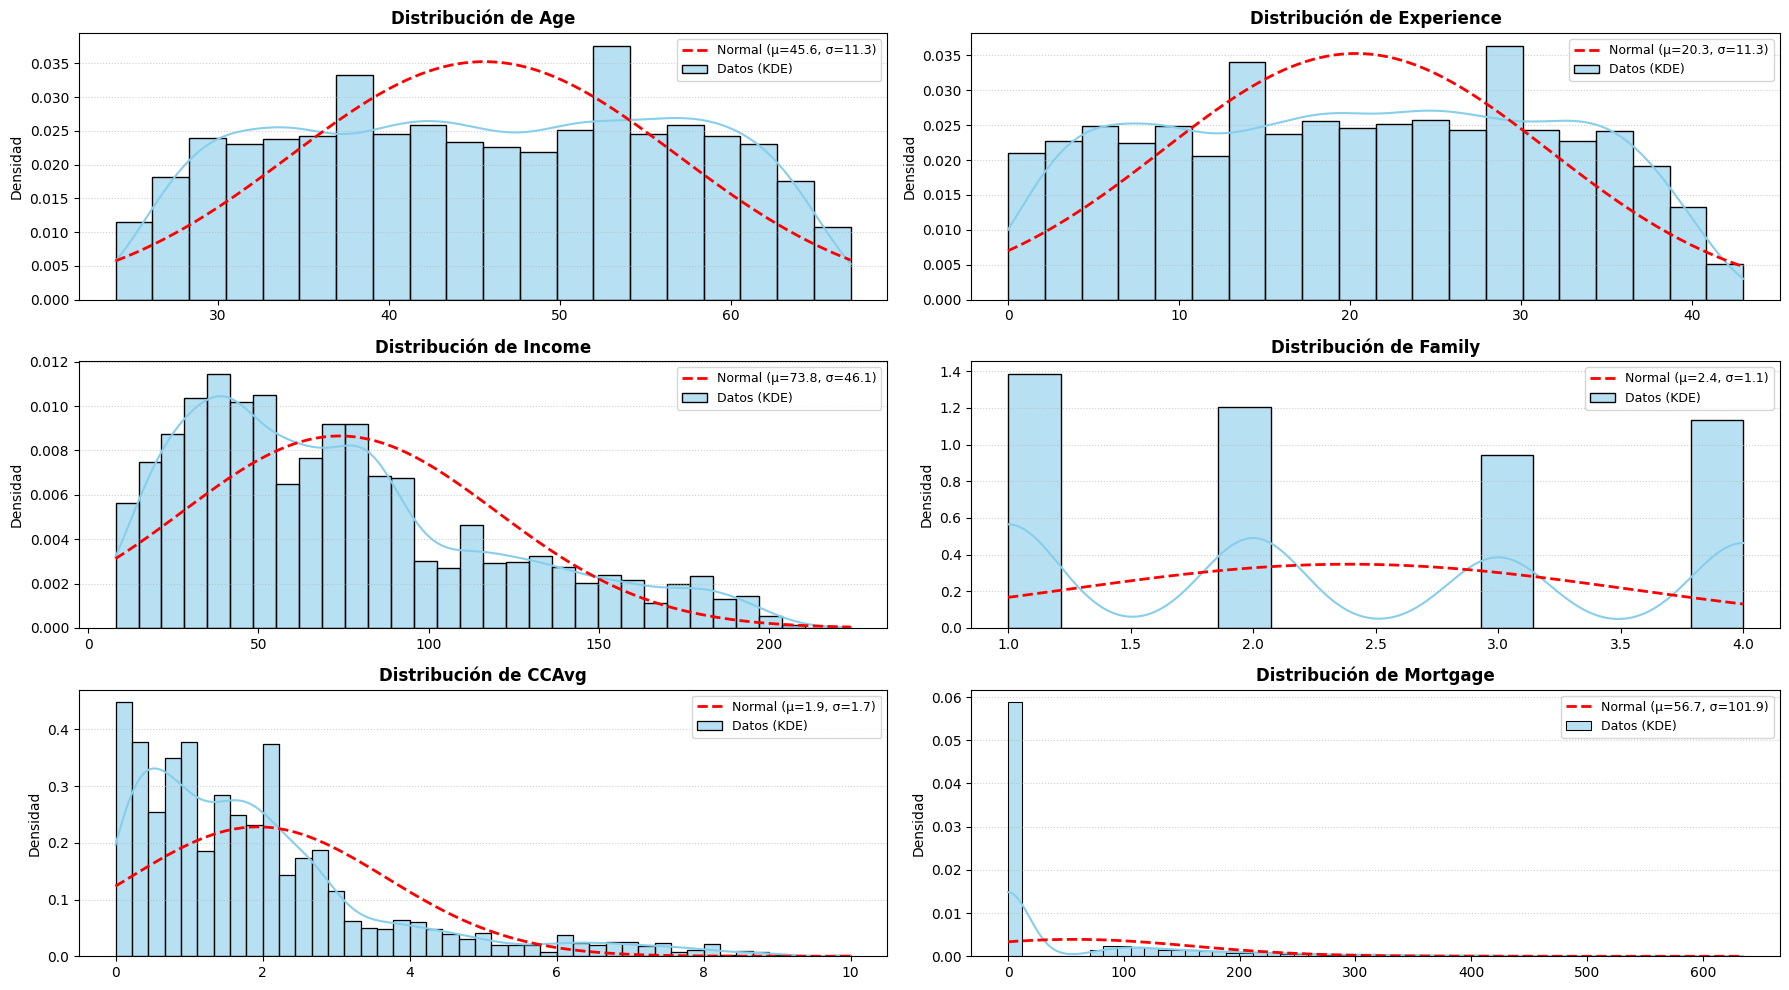

In [52]:
# 1. Definir la lista de variables numéricas a graficar
variables_numericas = ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']

# 2. Configurar la cuadrícula de subplots (2 filas, 3 columnas)
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(18, 10))
axes = axes.flatten()  # Aplanar la matriz de ejes para iterar fácilmente

# 3. Ciclo para construir cada gráfico
for i, col in enumerate(variables_numericas):
    # Eliminar valores nulos para el cálculo matemático de las curvas
    datos_col = loan_df[col].dropna()

    # Graficar el Histograma y la curva KDE (ambas normalizadas usando stat='density')
    sns.histplot(datos_col, kde=True, stat="density", color="skyblue",
                 alpha=0.6, ax=axes[i], label="Datos (KDE)")

    # Calcular los parámetros para la Distribución Normal Teórica de referencia
    mu, std = stats.norm.fit(datos_col)

    # Crear un rango de valores X en base al mínimo y máximo de la columna
    x = np.linspace(datos_col.min(), datos_col.max(), 100)
    # Generar la campana de Gauss teórica
    p = stats.norm.pdf(x, mu, std)

    # Graficar la curva Normal de referencia (Línea discontinua roja)
    axes[i].plot(x, p, 'r--', linewidth=2, label=f"Normal (μ={mu:.1f}, σ={std:.1f})")

    # Personalización estética de cada subplot
    axes[i].set_title(f"Distribución de {col}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Densidad")
    axes[i].legend(fontsize=9)
    axes[i].grid(axis='y', linestyle=':', alpha=0.6)

# Ajustar el diseño para evitar que los textos se encimen
plt.tight_layout()
plt.show()




*   **Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.**

    *   `Age`: Con un resultado de simetria de -0.023	se consiera simétrica, mientras que con una curtosis de -1.161, se considera platicúrtica (achatada). **Los valores númericos No coinciden con el gráfico.**
    *  `Income`: Con una simetria  de 0.842	se considera ligeramente asimetríca con sesgo a la derecha. Mientras que con una curtosis de	-0.046 se clasifica como Mesocúrtica.**Los valores númericos coinciden con el gráfico.**
    * `Mortgage`: Con una asimetria de	2.104	se considera con sesgo a la derecha  y una curtosis de	4.761 se clasifica como leptocúrtica, es decir muy apuntada. **Los valores númericos coinciden con el gráfico.**





*   **Para cada variable, crea un gráfico de boxplot individual que incluya la media.**



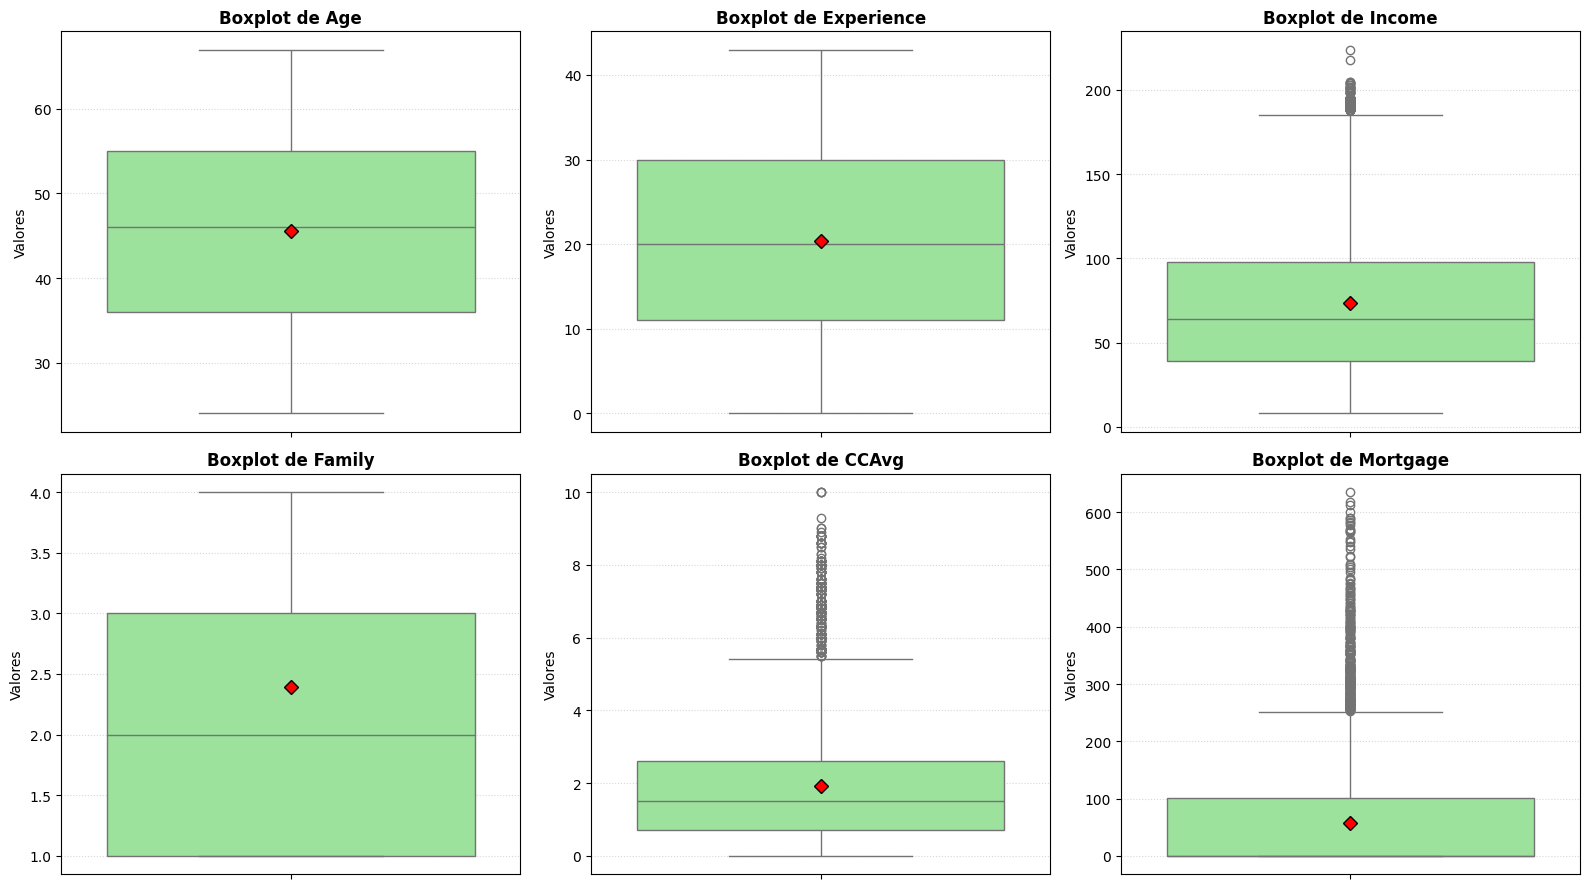

In [53]:
# De nuevo, se define la lista de variables numéricas a graficar
variables_numericas = ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']

# Configurar  cuadrícula de subplots (2 filas, 3 columnas)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 9))
axes = axes.flatten()  # Aplanar la matriz para iterar en un solo ciclo

# ciclo para construir cada gráfico de caja individual
for i, col in enumerate(variables_numericas):
    sns.boxplot(
        y=loan_df[col],
        ax=axes[i],
        color="lightgreen",
        showmeans=True,  # Habilita que se dibuje la media
        meanprops={
            "marker": "D",               # Marcador en forma de Diamante para la media
            "markerfacecolor": "red",     # Color de relleno rojo
            "markeredgecolor": "black",   # Borde negro para el diamante
            "markersize": 7               # Tamaño del marcador
        }
    )
    # Personalización estética de cada subplot
    axes[i].set_title(f"Boxplot de {col}", fontsize=12, fontweight='bold')
    axes[i].set_ylabel("Valores")
    axes[i].grid(axis='y', linestyle=':', alpha=0.5)

# Ajustar el espacio entre los gráficos para que no se amontona
plt.tight_layout()
plt.show()



*   **Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?**



In [54]:
# Estadísticas descriptivas de las variables numéricas, incluyendo asimetria y curtosis
variables_numericas = loan_df.select_dtypes(include=['number'])
est_descritiva=loan_df.describe().T
est_descritiva['simetria'] = variables_numericas.skew()
est_descritiva['curtosis'] = variables_numericas.kurt()
est_descritiva

,count,mean,std,min,25%,50%,75%,max,simetria,curtosis
Age,4942.0,45.561311,11.314736,24.0,36.0,46.0,55.0,67.0,-0.023024,-1.161379
Experience,4942.0,20.336301,11.307402,0.0,11.0,20.0,30.0,43.0,-0.015453,-1.134596
Income,4942.0,73.815864,46.108226,8.0,39.0,64.0,98.0,224.0,0.842132,-0.046006
Family,4942.0,2.391947,1.148356,1.0,1.0,2.0,3.0,4.0,0.159089,-1.404189
CCAvg,4942.0,1.935585,1.748332,0.0,0.7,1.5,2.6,10.0,1.594922,2.636409
Mortgage,4942.0,56.652165,101.868229,0.0,0.0,0.0,101.0,635.0,2.104183,4.761586




*   **Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?**
La relación entre la media y la mediana (cuartil dos o 50%) puede dar un buen entendimiento sobre el sesgo, positivo o a la derecha (cuando el valor de la media es mayor que la mediana) o negativo o a la izquierda, cuando el valor de la media es menor que la mediana. Como se aprecia la variable  `Age`, tiene valores similares (Media 45 y mediana 46), por tanto se puede decir que es simetrica sin sesgo. La variable `Experience`tiene valores similares (Media 20 y mediana 20), por tanto se puede decir que es simetrica sin sesgo. La variable `Income`tiene valores bastante diferentes (Media 73 > mediana 64), por tanto se puede decir que presenta un sesgo postivo o a la derecha. La variable `Mortgage`tiene valores bastante diferentes (Media 56 > mediana 0), por tanto se puede decir que presenta un sesgo postivo o a la derecha.


8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

In [55]:
#Estadísticas descriptivas variables categóricas
df_categoricas = loan_df.select_dtypes(include=['category']).describe().T
df_categoricas

,count,unique,top,freq
Education,4942,3,1,2079
Personal Loan,4942,2,0,4463
Securities Account,4942,2,0,4427
CD Account,4942,2,0,4641
Online,4942,2,1,2952
CreditCard,4942,2,0,3489


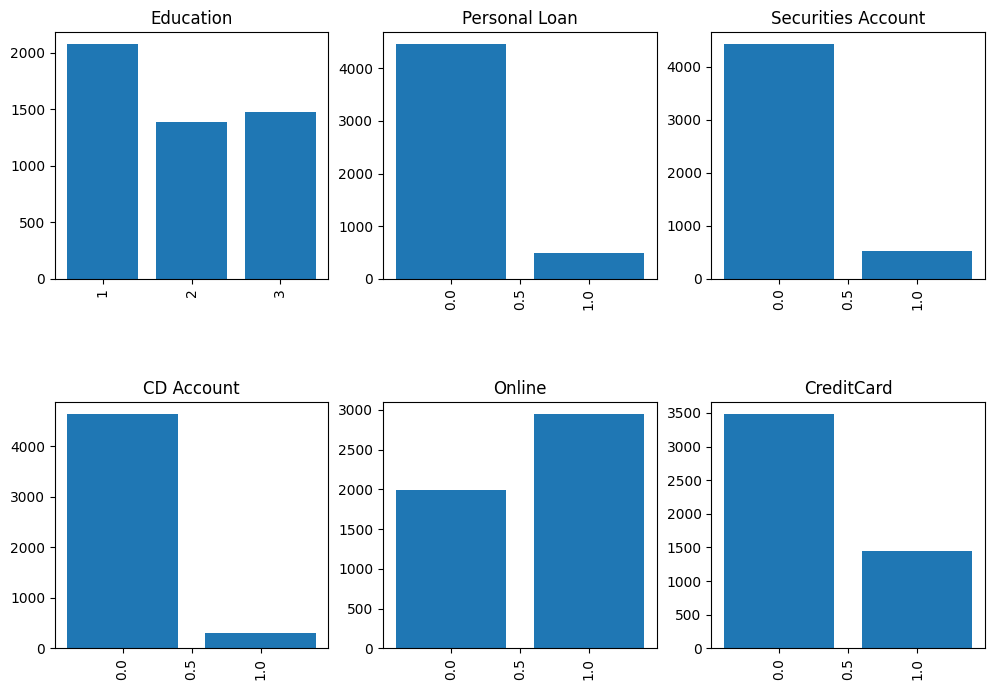

In [56]:
#gráfico de barras para cada variable
cat_cols= loan_df.select_dtypes(include=['category']).columns.tolist()
fig, axes = plt.subplots(2,3, figsize=(12,8))
plt.subplots_adjust(hspace=0.5)
axes = axes.ravel()
for col, ax in zip(loan_df[cat_cols], axes):
  value_counts = loan_df[col].value_counts()
  ax.bar(value_counts.index, value_counts.values) # ---> Matplotlib
  ax.set(title=f'{col}', xlabel=None)
  ax.tick_params(axis='x',rotation=90)

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

Generando matriz de gráficos de dispersión... (Esto puede tomar unos segundos)


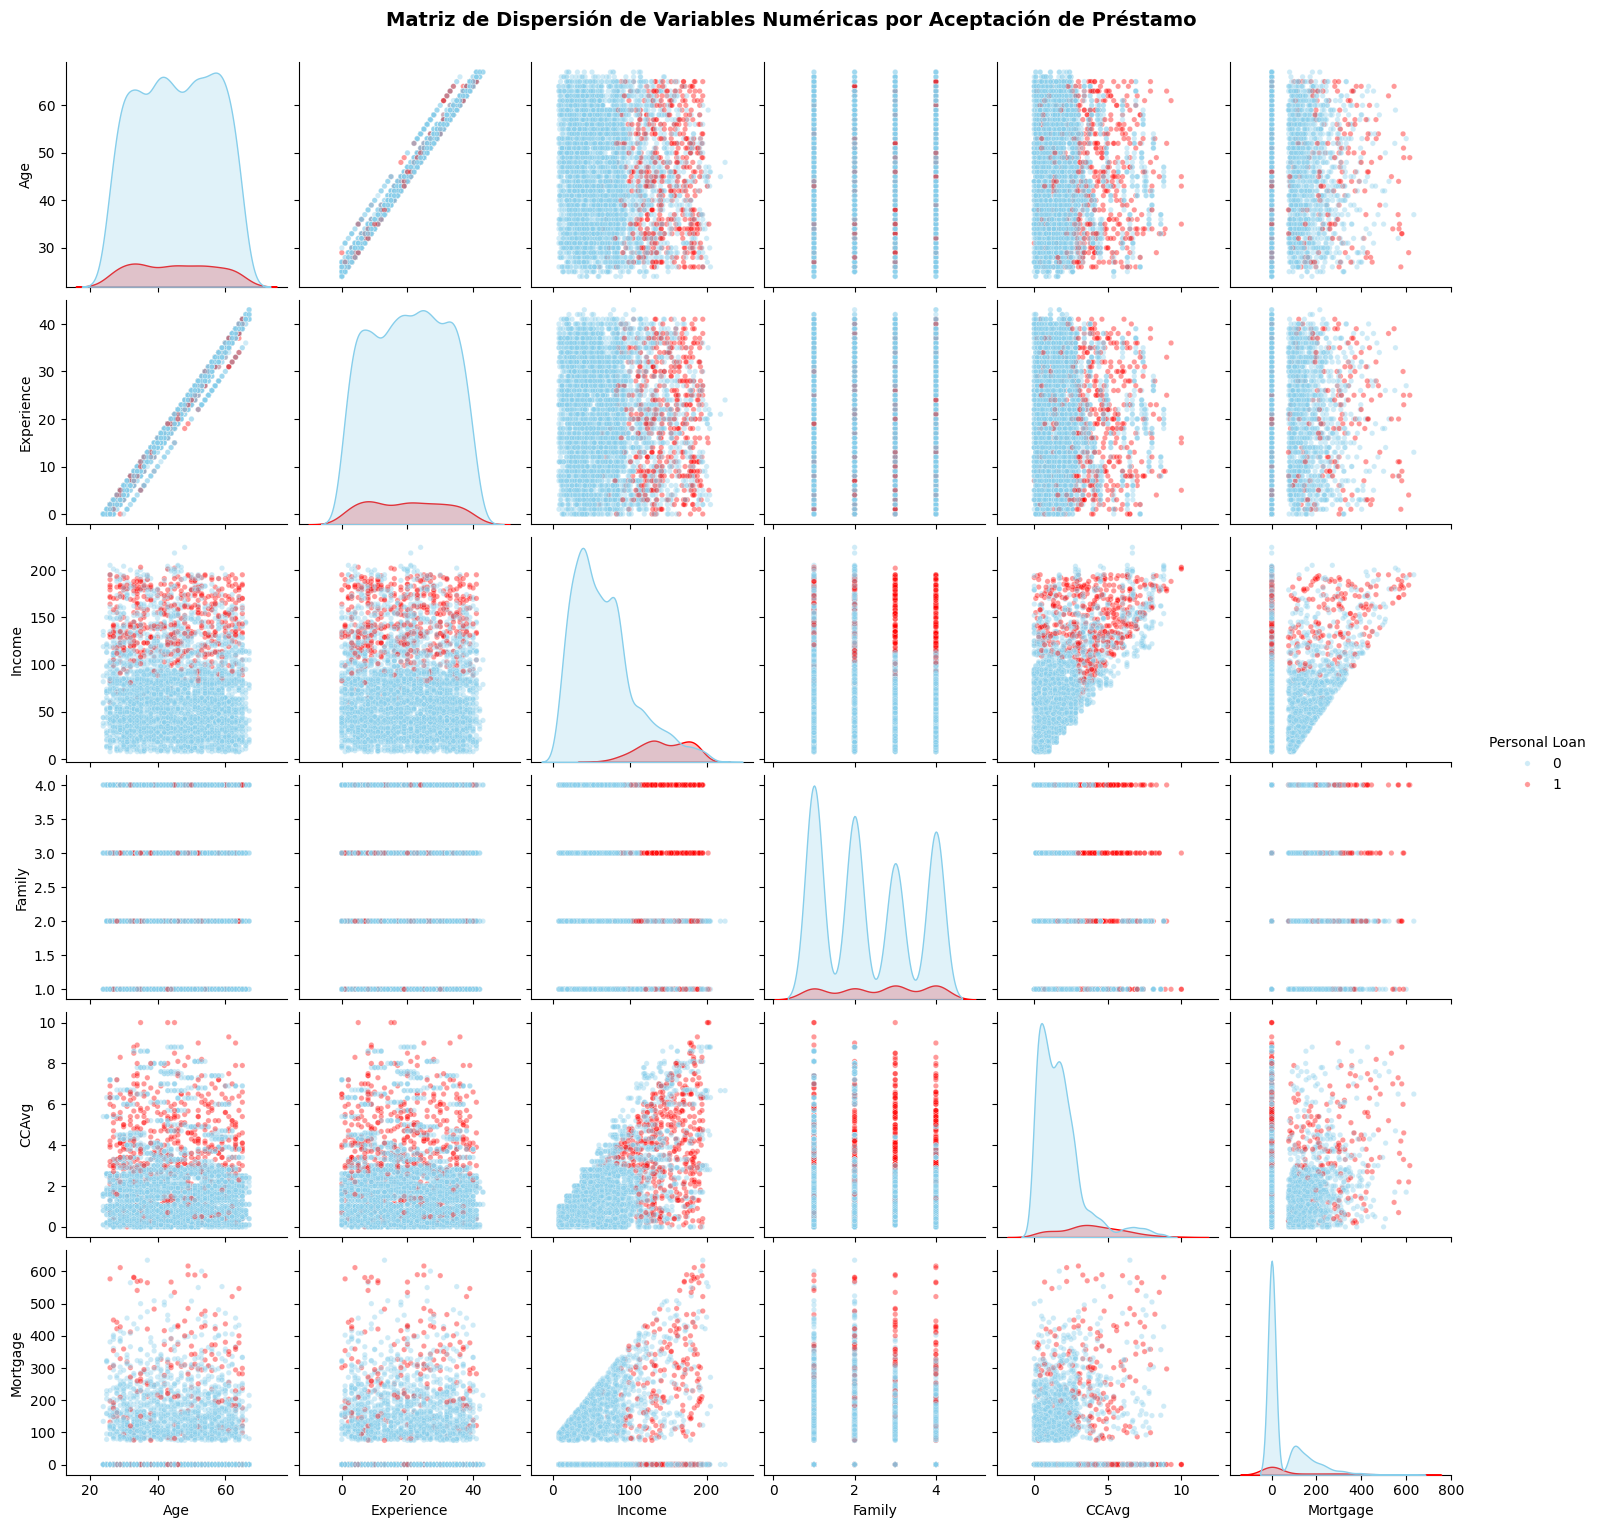

In [57]:
variables_numericas = ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']

# Se agrega 'Personal Loan' para usarla como etiqueta de color (hue)
# Aseguramos que incluimos la columna objetivo para el análisis visual
columnas_analisis = variables_numericas + ['Personal Loan']

# matriz de dispersión (pairplot)
print("Generando matriz de gráficos de dispersión... (Esto puede tomar unos segundos)")
grid_dispersio = sns.pairplot(
    loan_df[columnas_analisis],
    hue='Personal Loan',
    palette={0: 'skyblue', 1: 'red'},
    diag_kind='kde',
    plot_kws={'alpha': 0.4, 's': 15}  # Transparencia y tamaño de puntos para evitar solapamiento
)

# Ajustes estéticos generales
grid_dispersio.fig.suptitle("Matriz de Dispersión de Variables Numéricas por Aceptación de Préstamo", y=1.02, fontsize=14, fontweight='bold')
plt.show()



*   **Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes**

Como se puede observar existe una evidente relación entre las variables `Age` (edad) y `Experience`(experiencia); entre el `Income` (ingreso anual del cliente en miles de pesos) y su `CCAvg`(promedio de gasto mensual con tarjeta de credito) y la vairable `Mortgage` (valor de la hipoteca); finalmente se evidencia una relacion entre las variables `Family` (número de miembros de la familia) y `Personal Loan` (si el cliente aceptó (1) o no (0) un préstamo personal).
* Para el primer caso, `Age` (edad) y `Experience`(experiencia), la relación es positiva, lo cual es evidente, a mas edad más experiencia.
* Para el caso dos;  `Income` (ingreso anual del cliente en miles de pesos), `CCAvg`(promedio de gasto mensual con tarjeta de credito) y Mortgage` (valor de la hipoteca); la correlación tambien es positiva, entre mayor es el ingreso, en promedio, mayor es el gasto mensual, así como el valoir de un hipoteca.
* Para el caso 3; la relacion entre `Family` (número de miembros de la familia) y `Personal Loan` (si el cliente aceptó (1) o no (0) un préstamo personal), tambien es positiva, más cuando se analiza desde la interseccion con la variable `CCAvg`(promedio de gasto mensual con tarjeta de credito).

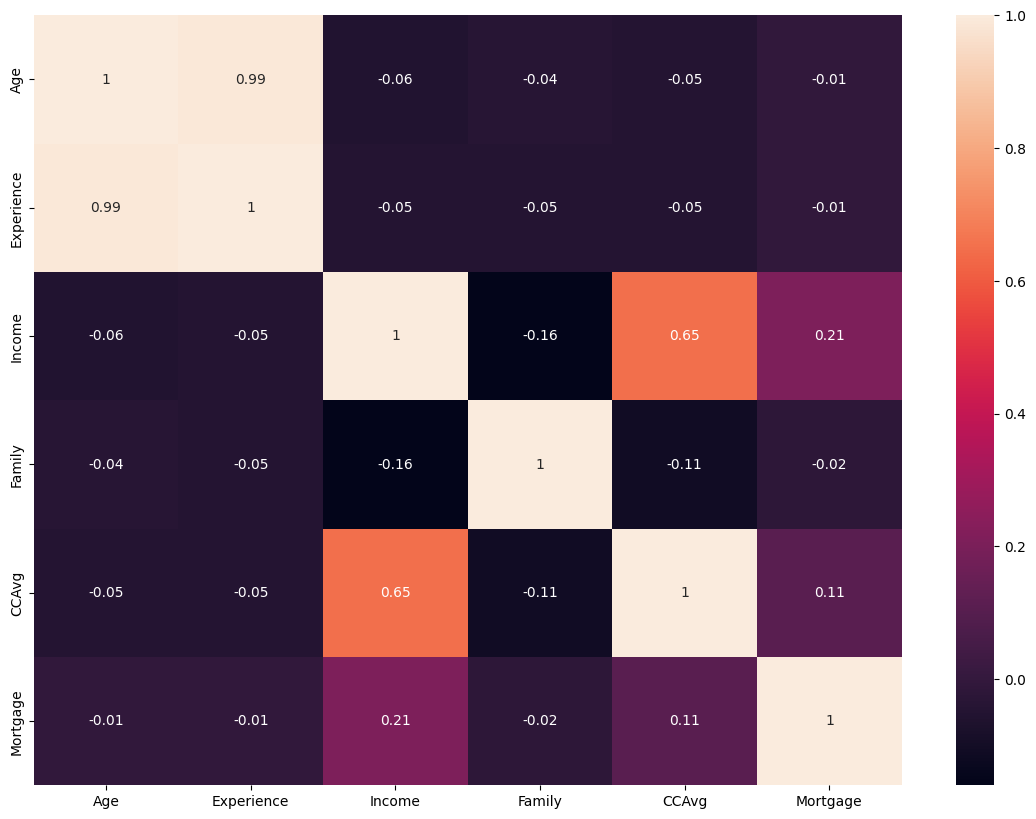

In [58]:
plt.figure(figsize = (14, 10))
sns.heatmap(round(loan_df.corr(numeric_only=True),2), annot = True) # ---> Seaborn
plt.show()

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.




*   **Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`**



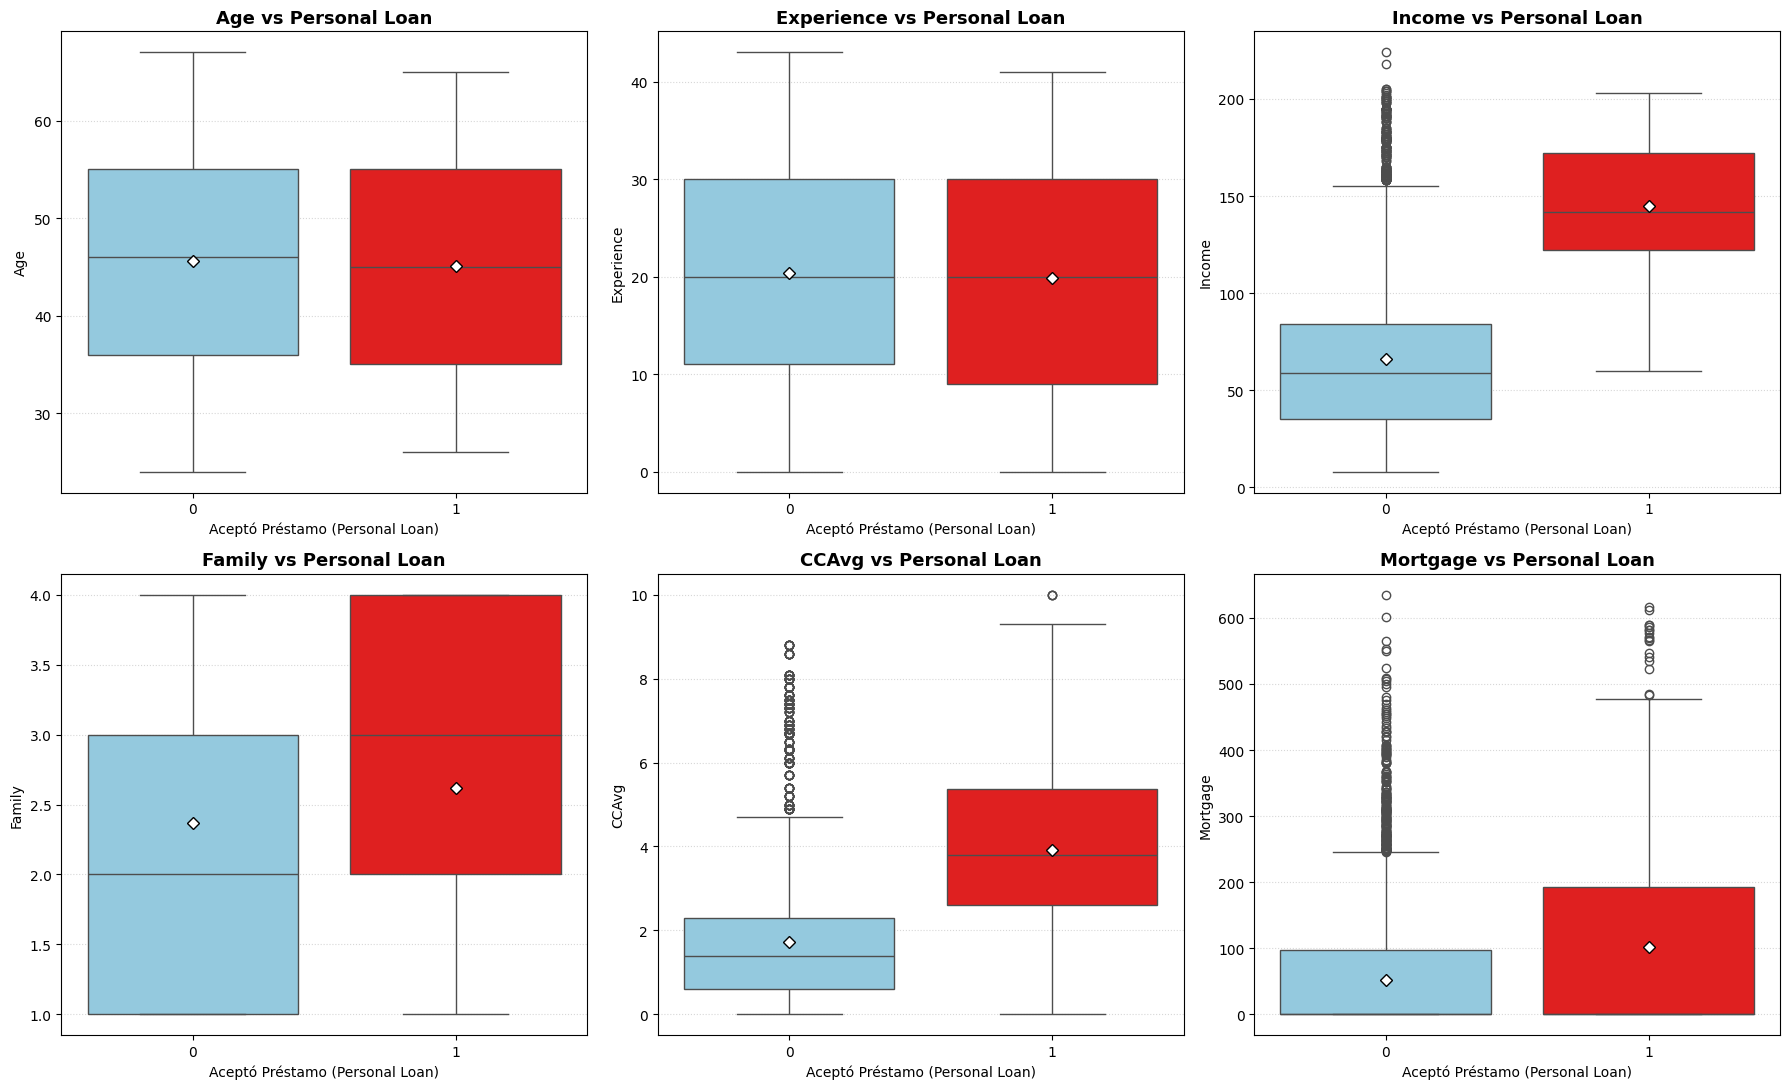

In [59]:
variables_numericas = ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']

# configurar cuadrícula de subplots (2 filas, 3 columnas)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 11))
axes = axes.flatten()

# ciclo para generar los boxplot de cada variable según los valores de 'Personal Loan'
for i, col in enumerate(variables_numericas):
    sns.boxplot(
        x='Personal Loan', y=col, data=loan_df, ax=axes[i], palette={0: "skyblue", 1: "red"},
        hue='Personal Loan', legend=False, showmeans=True,
        meanprops={
            "marker": "D",
            "markerfacecolor": "white",
            "markeredgecolor": "black",
            "markersize": 6
        }
    )

    # ajustes para cada gráfico
    axes[i].set_title(f"{col} vs Personal Loan", fontsize=13, fontweight='bold')
    axes[i].set_xlabel("Aceptó Préstamo (Personal Loan)")
    axes[i].set_ylabel(col)
    axes[i].grid(axis='y', linestyle=':', alpha=0.5)

# Ajustar el diseño de la cuadrícula
plt.tight_layout()
plt.show()




*   **Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.**



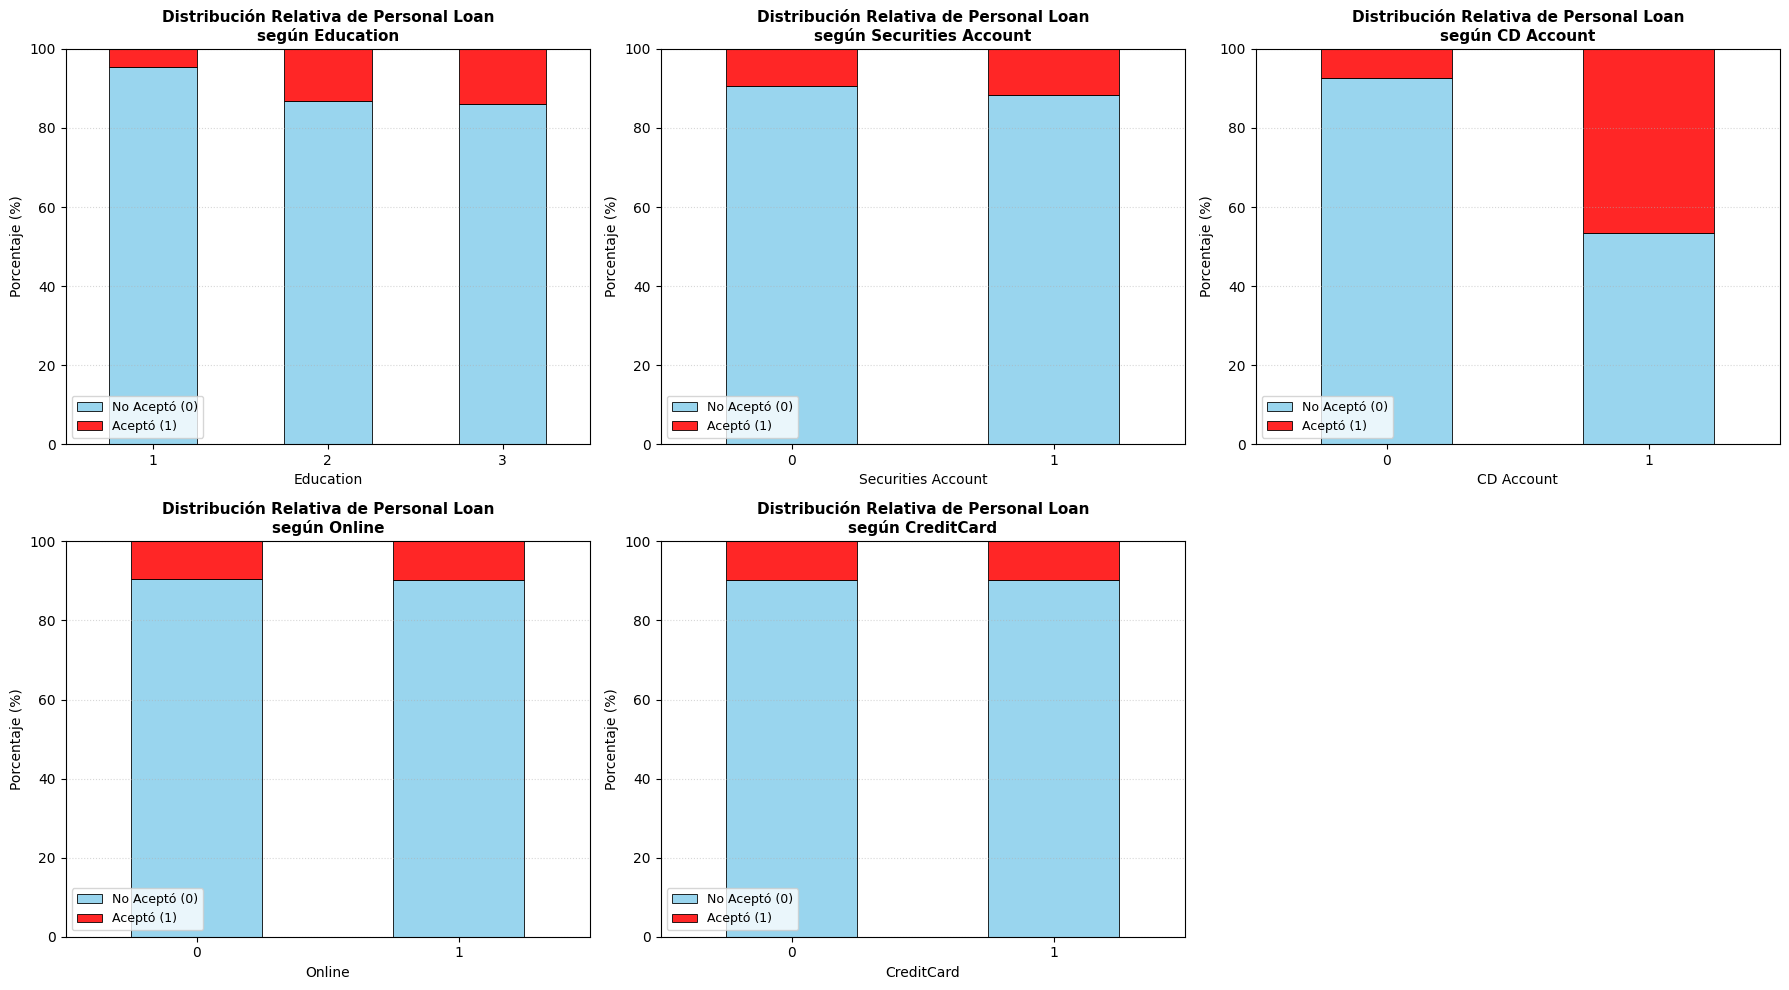

In [60]:
variables_categoricas = ['Education', 'Securities Account', 'CD Account', 'Online', 'CreditCard']

# configurar la cuadrícula de gráficos (2 filas, 3 columnas para cubrir las 5 variables)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()

# ciclo para calcular las distribuciones relativas y graficar
for i, col in enumerate(variables_categoricas):
    #  tabla de frecuencias cruzadas
    tabla_contingencia = pd.crosstab(loan_df[col], loan_df['Personal Loan'])

    # convertir las frecuencias absolutas a porcentajes
    tabla_relativa = tabla_contingencia.div(tabla_contingencia.sum(axis=1), axis=0) * 100

    # graficar las barras apiladas
    tabla_relativa.plot(
        kind='bar',
        stacked=True,
        ax=axes[i],
        color=['skyblue', 'red'],
        alpha=0.85,
        edgecolor='black',
        linewidth=0.7
    )

    # ajustes de cada subplot
    axes[i].set_title(f"Distribución Relativa de Personal Loan\nsegún {col}", fontsize=11, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Porcentaje (%)")
    axes[i].set_ylim(0, 100)
    axes[i].tick_params(axis='x', rotation=0)  # Mantener etiquetas horizontales para mejor lectura
    axes[i].grid(axis='y', linestyle=':', alpha=0.5)

    # configuración de la leyenda
    axes[i].legend(['No Aceptó (0)', 'Aceptó (1)'], loc='lower left', fontsize=9)

# eliminar el último subplot vacío de la cuadrícula de 3x2
fig.delaxes(axes[-1])

# ajustes de diseño de los espacios
plt.tight_layout()
plt.show()




*   **Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados**

Conforme a las variables analizadas en los graficos anteriores se puede realizar un perfilamiento de las variables que tienen un alto impacto para poder predecir quien tomara el prestamo personal (`Personal Loan`). Dentro de las variables con mayor impacto se encuentran: `Income`,  `CCVag` y `Mortgage`: esto indica que las personas con más ingresos son los que tienen mayor tendencia a aceptar los prestamos personal, tambien aquellos con un alto promedio de gasto en tarjeta de credito, asi como quienes tienen montos de hipoteca más altos. En conjunto muestra que tener altos ingresos presenta mejores condiciones para prestamos personales dada en la capacidad para respaldarlos, asi como contar con colaterales financieros y experiencia crediticia importante para amparar el pago de los prestamos. Un segundo nivel de analisis muestra que los prestamos tienden a estar asociados a la variable `Family`, lo que muestra que familias mas grandes, particularmente las mayores de 3 integrantes en comparación de aquellas que tienen cero integrantes, tienden a aceptar mas el credito personal.

 De otro lado, al analizar las variables categoricas, el mayor contraste se da en la variable `CD Account`lo que muestra que quienes tienen una cuenta de deposito tienden a tomar los prestamos personales. Asimismo, aunque no tan marcado la variable `Education` muestra que a mayor nivel de educaciónse tiene mayor receptividad a tomar el credito personal. finalmente las variables `Online` y `CrediCard`muestran un tamaño similar lo que muestra que el uso de los servicios virtuales del banco y si es titular de una tarjeta de credito no hace mas probable que se tome un credito personal.


---

**Declaración de uso de IA**

Si aplica, deberá indicarse la herramienta y el modelo empleado en la entrega, así como la finalidad de su uso (generación de código / depuración / optimización).

Por ejemplo:

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración. https://chat.openai.com/

---